# 05 – Shape Function Vergleich (Herzstück)

**Ziel:** Gegenüberstellung der IGANN- und EBM-Shape-Functions für beide Targets
- **Modell A (Preis):** Was treibt den Mietpreis in €/m²?
- **Modell B (Laufzeit):** Was treibt die Nachfrageresonanz (Zeit bis zur Vermietung)?
- **Vergleich mit SHAP** (XGBoost) als Black-Box-Referenz

**Abhängigkeiten:**
```
NB03 (Cell 14) → data/processed/shapes_igann_price.parquet
               → data/processed/shapes_ebm_price.parquet
NB04 (Cell 14) → data/processed/shapes_igann_duration.parquet
               → data/processed/shapes_ebm_duration.parquet
```
> Hinweis: Alle y-Werte aus Modell B sind auf log1p(laufzeittage)-Skala.

In [ ]:
import sys, os
import warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# ── Pfade ──────────────────────────────────────────────────────────────────
SHAPES_DIR = '../data/processed'
MODELS_DIR = '../models'

SHAPE_FILES = {
    ('IGANN', 'price'):    'shapes_igann_price.parquet',
    ('EBM',   'price'):    'shapes_ebm_price.parquet',
    ('IGANN', 'duration'): 'shapes_igann_duration.parquet',
    ('EBM',   'duration'): 'shapes_ebm_duration.parquet',
}

# ── Laden ──────────────────────────────────────────────────────────────────
shapes = {}
for (model, target), fname in SHAPE_FILES.items():
    path = os.path.join(SHAPES_DIR, fname)
    if os.path.exists(path):
        shapes[(model, target)] = pd.read_parquet(path)
        n_feat = shapes[(model, target)]['feature'].nunique()
        print(f'   {fname}  ({n_feat} Features)')
    else:
        shapes[(model, target)] = None
        print(f'   {fname} nicht vorhanden — NB03/04 zuerst ausführen')

missing = [k for k, v in shapes.items() if v is None]
if missing:
    print(f'\n  {len(missing)} Datei(en) fehlen. Nur verfügbare Daten werden analysiert.')
else:
    print('\n Alle 4 Shape-Parquets geladen — ready für Analyse.')

  ✅ shapes_igann_price.parquet  (38 Features)
  ✅ shapes_ebm_price.parquet  (38 Features)
  ✅ shapes_igann_duration.parquet  (38 Features)
  ✅ shapes_ebm_duration.parquet  (38 Features)

✅ Alle 4 Shape-Parquets geladen — ready für Analyse.


In [2]:
# Welche Features sind in welchen Modellen vorhanden?
print('Feature-Verfügbarkeit:')
print('-' * 60)

feature_sets = {}
for (model, target), df in shapes.items():
    if df is not None:
        feats = set(df['feature'].unique())
        feature_sets[(model, target)] = feats
        print(f'  {model:5s} | {target:8s} | {len(feats):2d} Features')

# Gemeinsame Features über alle Modelle (Schnittmenge)
all_sets = [v for v in feature_sets.values()]
if len(all_sets) >= 2:
    common_features = sorted(all_sets[0].intersection(*all_sets[1:]))
    print(f'\nGemeinsame Features (in allen Modellen): {len(common_features)}')
    for f in common_features:
        print(f'  - {f}')

igann_p = feature_sets.get(('IGANN', 'price'), set())
ebm_p   = feature_sets.get(('EBM',   'price'), set())
if igann_p - ebm_p: print(f'Nur in IGANN: {sorted(igann_p - ebm_p)}')
if ebm_p - igann_p: print(f'Nur in EBM:   {sorted(ebm_p - igann_p)}')

Feature-Verfügbarkeit:
------------------------------------------------------------
  IGANN | price    | 38 Features
  EBM   | price    | 38 Features
  IGANN | duration | 38 Features
  EBM   | duration | 38 Features

Gemeinsame Features (in allen Modellen): 38
  - ajahr
  - alter_bauwerk
  - amonat
  - anzahletagen
  - aufzug
  - ausstattung
  - badezimmer
  - balkon
  - blid
  - completeness_score
  - denkmalobjekt
  - dens_park
  - dens_supermarket
  - dens_transit
  - dist_park
  - dist_supermarket
  - dist_to_center
  - dist_transit
  - einbaukueche
  - energieeffizienzklasse
  - erg_amd
  - etage
  - foerderung
  - freiab_monate
  - gaestewc
  - garten
  - hat_energieausweis
  - haustier_erlaubt
  - heizungsart
  - kategorie_Wohnung
  - keller
  - objektzustand
  - parkplatz
  - rollstuhlgerecht
  - schlafzimmer
  - wohnflaeche
  - wurde_modernisiert
  - zimmeranzahl


In [3]:
def get_shape(model, target, feature):
    """Gibt (x, y) als numpy-Arrays oder (None, None) zurück."""
    df = shapes.get((model, target))
    if df is None:
        return None, None
    sub = df[df['feature'] == feature]
    if sub.empty:
        return None, None
    return sub['x'].to_numpy(dtype=float), sub['y'].to_numpy(dtype=float)


def plot_shape_comparison(features, suptitle='', figsize_per_row=(14, 3.5)):
    """
    Für jedes Feature: 2 Subplots (Preis | Laufzeit), je IGANN + EBM überlagert.
    """
    n = len(features)
    if n == 0:
        print('Keine Features zum Plotten.')
        return None
    fig, axes = plt.subplots(n, 2, figsize=(figsize_per_row[0], figsize_per_row[1] * n),
                             squeeze=False)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, fontweight='bold', y=1.01)

    colors = {'IGANN': '#636EFA', 'EBM': '#EF553B'}
    targets_info = [('price', 'Preis (€/m²)'), ('duration', 'Laufzeit (log₁p Tage)')]

    for row, feat in enumerate(features):
        for col, (target, t_label) in enumerate(targets_info):
            ax = axes[row][col]
            plotted = False
            for model in ['IGANN', 'EBM']:
                x, y = get_shape(model, target, feat)
                if x is not None:
                    order = np.argsort(x)
                    ax.plot(x[order], y[order], color=colors[model],
                            label=model, linewidth=2, alpha=0.85)
                    ax.axhline(0, color='gray', linewidth=0.7, linestyle='--')
                    plotted = True
            if not plotted:
                ax.text(0.5, 0.5, 'Daten fehlen', ha='center', va='center',
                        transform=ax.transAxes, color='gray')
            if row == 0:
                ax.set_title(t_label, fontsize=11, fontweight='bold')
            ax.set_xlabel(feat)
            ax.set_ylabel('Effekt' if col == 0 else '')
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)

    plt.tight_layout()
    return fig

In [ ]:
# Effektamplitude = max(y) - min(y) pro Feature und Modell
amplitude_records = []
for (model, target), df in shapes.items():
    if df is None:
        continue
    for feat, grp in df.groupby('feature'):
        amp = grp['y'].max() - grp['y'].min()
        amplitude_records.append({
            'model': model, 'target': target,
            'feature': feat, 'amplitude': amp,
        })

df_amp = pd.DataFrame(amplitude_records)

if not df_amp.empty:
    print('=== Top-10 Features nach Effektamplitude ===')
    for (model, target), grp in df_amp.groupby(['model', 'target']):
        top = grp.nlargest(10, 'amplitude')
        print(f'\n{model} | {target}:')
        for _, row in top.iterrows():
            print(f'  {row["feature"]:30s}  Δ={row["amplitude"]:.4f}')
else:
    print(' Noch keine Shape-Daten vorhanden.')

=== Top-10 Features nach Effektamplitude ===

EBM | duration:
  erg_amd                         Δ=1.7221
  denkmalobjekt                   Δ=1.1983
  wohnflaeche                     Δ=1.1414
  ajahr                           Δ=1.1102
  blid                            Δ=1.0713
  freiab_monate                   Δ=0.8804
  completeness_score              Δ=0.7555
  anzahletagen                    Δ=0.7117
  dens_park                       Δ=0.5946
  dist_supermarket                Δ=0.5371

EBM | price:
  wohnflaeche                     Δ=9.1270
  ajahr                           Δ=6.7896
  etage                           Δ=5.7156
  blid                            Δ=5.3563
  dens_park                       Δ=5.1395
  erg_amd                         Δ=4.4076
  dens_supermarket                Δ=4.0949
  anzahletagen                    Δ=3.2697
  ausstattung                     Δ=3.1708
  dens_transit                    Δ=3.1059

IGANN | duration:
  denkmalobjekt                   Δ=1.8094
  

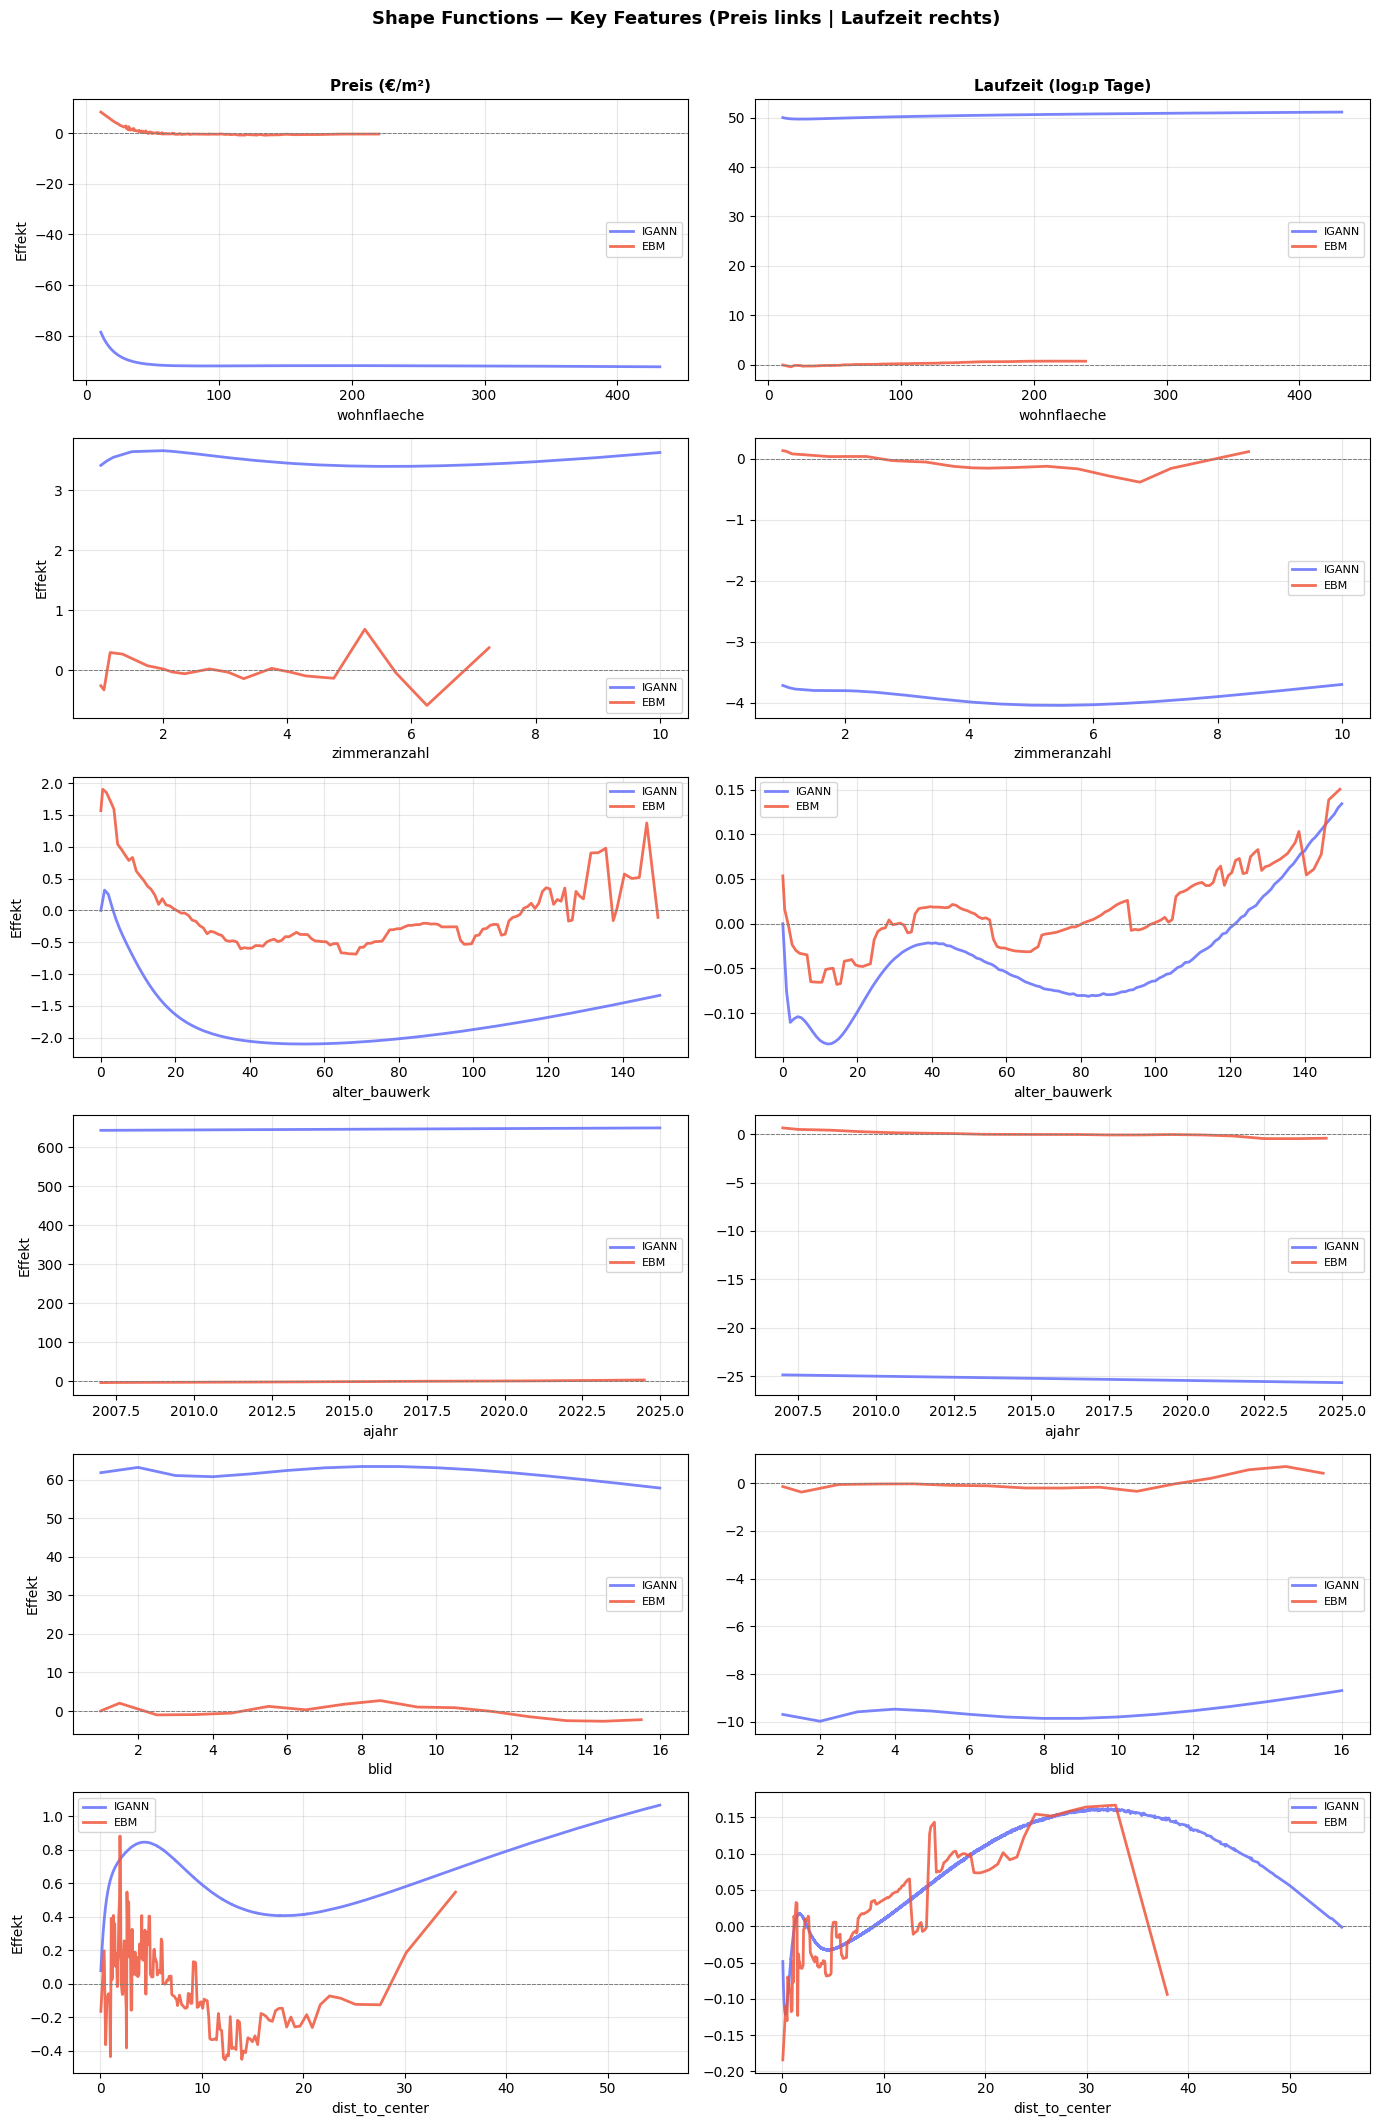

Plot gespeichert: shape_comparison_key.png (6 Features)


In [5]:
KEY_FEATURES = [
    'wohnflaeche', 'zimmeranzahl', 'alter_bauwerk',
    'ajahr',       'blid',         'dist_to_center',
]

# Nur tatsächlich vorhandene Features plotten
available_in_igann = set()
for key in [('IGANN', 'price'), ('IGANN', 'duration')]:
    if shapes.get(key) is not None:
        available_in_igann |= set(shapes[key]['feature'].unique())

plot_features = [f for f in KEY_FEATURES if f in available_in_igann]

if plot_features:
    fig = plot_shape_comparison(
        plot_features,
        suptitle='Shape Functions — Key Features (Preis links | Laufzeit rechts)'
    )
    if fig:
        os.makedirs(SHAPES_DIR, exist_ok=True)
        fig.savefig(f'{SHAPES_DIR}/shape_comparison_key.png', dpi=150, bbox_inches='tight')
        plt.show()
        print(f'Plot gespeichert: shape_comparison_key.png ({len(plot_features)} Features)')
else:
    print('⏳ Shape-Daten noch nicht verfügbar — NB03/04 ausführen.')

In [6]:
# Normierter Vergleich: Korrelation der Shape-Effekte zwischen Price und Duration
# Positive Korrelation → Feature treibt beides in dieselbe Richtung
# Negative Korrelation → Feature treibt Preis hoch, Laufzeit runter (oder umgekehrt)

print('=== Preis vs. Laufzeit: Richtungsübereinstimmung der Shape-Effekte ===')

correlation_records = []
for model in ['IGANN', 'EBM']:
    df_p = shapes.get((model, 'price'))
    df_d = shapes.get((model, 'duration'))
    if df_p is None or df_d is None:
        print(f'  {model}: Daten fehlen (price oder duration)')
        continue
    common = set(df_p['feature'].unique()) & set(df_d['feature'].unique())
    for feat in sorted(common):
        xp, yp = get_shape(model, 'price', feat)
        xd, yd = get_shape(model, 'duration', feat)
        if xp is None or xd is None or len(xp) < 3 or len(xd) < 3:
            continue
        x_min = max(xp.min(), xd.min())
        x_max = min(xp.max(), xd.max())
        if x_max <= x_min:
            continue
        x_grid = np.linspace(x_min, x_max, 50)
        yp_i = np.interp(x_grid, np.sort(xp), yp[np.argsort(xp)])
        yd_i = np.interp(x_grid, np.sort(xd), yd[np.argsort(xd)])
        if yp_i.std() < 1e-10 or yd_i.std() < 1e-10:
            continue
        corr = np.corrcoef(yp_i, yd_i)[0, 1]
        correlation_records.append({'model': model, 'feature': feat, 'corr': corr})

if correlation_records:
    df_corr = pd.DataFrame(correlation_records)
    for model, grp in df_corr.groupby('model'):
        print(f'\n{model} (n={len(grp)} Features):')
        pos_top = grp.nlargest(3, 'corr')
        neg_top = grp.nsmallest(3, 'corr')
        print('  Gleichlauf (Preis↑ & Laufzeit↑):')
        for _, r in pos_top.iterrows():
            print(f'    {r["feature"]:30s}  r={r["corr"]:+.3f}')
        print('  Gegenläufig (Preis↑ & Laufzeit↓):')
        for _, r in neg_top.iterrows():
            print(f'    {r["feature"]:30s}  r={r["corr"]:+.3f}')
else:
    print('⏳ Keine Shape-Daten für Korrelationsanalyse.')

=== Preis vs. Laufzeit: Richtungsübereinstimmung der Shape-Effekte ===

EBM (n=26 Features):
  Gleichlauf (Preis↑ & Laufzeit↑):
    ausstattung                     r=+0.958
    anzahletagen                    r=+0.845
    energieeffizienzklasse          r=+0.785
  Gegenläufig (Preis↑ & Laufzeit↓):
    dens_park                       r=-0.999
    ajahr                           r=-0.929
    completeness_score              r=-0.894

IGANN (n=26 Features):
  Gleichlauf (Preis↑ & Laufzeit↑):
    ausstattung                     r=+0.946
    freiab_monate                   r=+0.914
    energieeffizienzklasse          r=+0.902
  Gegenläufig (Preis↑ & Laufzeit↓):
    ajahr                           r=-1.000
    completeness_score              r=-0.992
    dens_supermarket                r=-0.986


Gegenläufige Features: ['ajahr', 'amonat', 'blid', 'completeness_score']


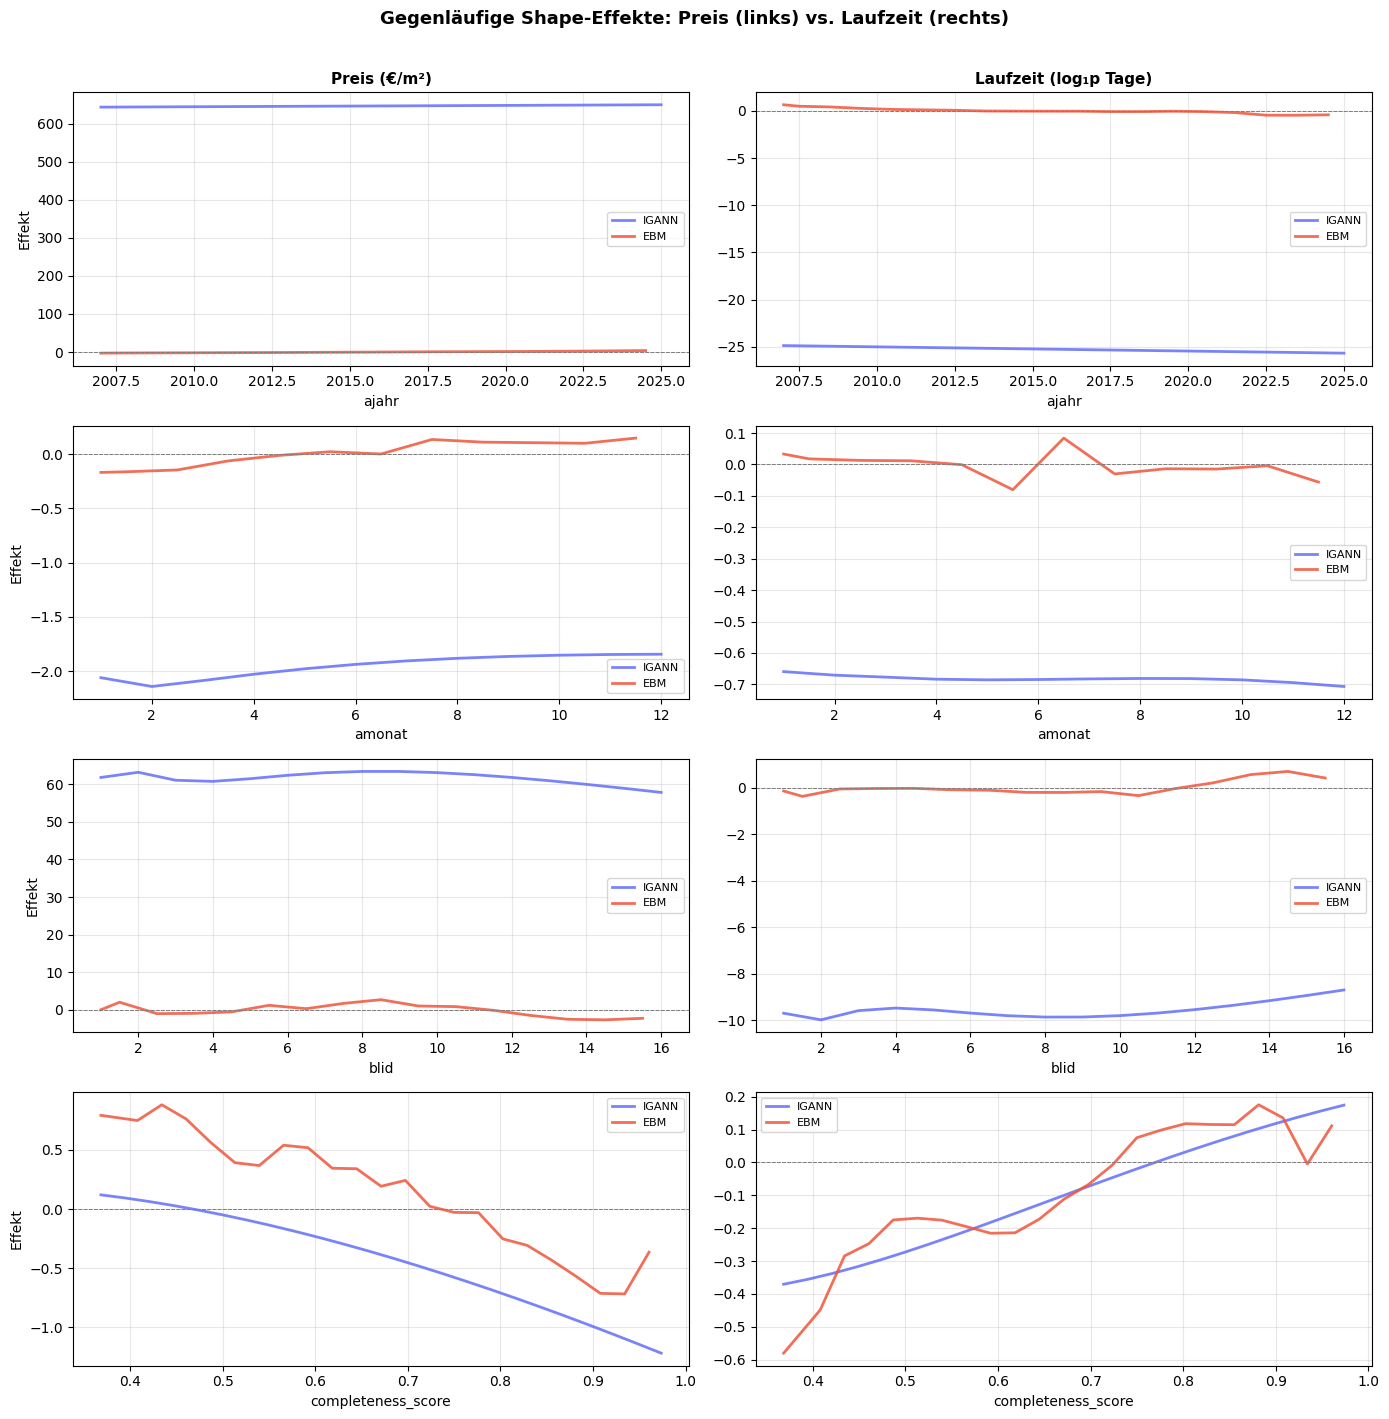

In [7]:
# Gegenläufige Features als Plot
if correlation_records:
    df_corr_all = pd.DataFrame(correlation_records)
    neg_feats = df_corr_all[df_corr_all['corr'] < -0.3]['feature'].unique()[:4].tolist()
    if neg_feats:
        print(f'Gegenläufige Features: {neg_feats}')
        fig = plot_shape_comparison(
            neg_feats,
            suptitle='Gegenläufige Shape-Effekte: Preis (links) vs. Laufzeit (rechts)'
        )
        if fig:
            fig.savefig(f'{SHAPES_DIR}/shape_counter_effects.png', dpi=150, bbox_inches='tight')
            plt.show()
    else:
        print('Keine stark gegenläufigen Features (Schwelle r < -0.3) gefunden.')
        print('→ Schwelle anpassen oder nach RUN_FINAL=True wiederholen.')
else:
    print('⏳ Bitte zuerst Zelle 7 (Korrelationsanalyse) ausführen.')

In [8]:
# Wie konsistent sind IGANN und EBM in ihren Shape-Schätzungen?
print('=== IGANN vs. EBM Shape-Konsistenz (Korrelation) ===')

consistency_records = []
for target in ['price', 'duration']:
    df_i = shapes.get(('IGANN', target))
    df_e = shapes.get(('EBM',   target))
    if df_i is None or df_e is None:
        print(f'  {target}: Daten fehlen')
        continue

    common = set(df_i['feature'].unique()) & set(df_e['feature'].unique())
    for feat in sorted(common):
        xi, yi = get_shape('IGANN', target, feat)
        xe, ye = get_shape('EBM',   target, feat)
        if xi is None or xe is None or len(xi) < 3 or len(xe) < 3:
            continue
        x_min = max(xi.min(), xe.min())
        x_max = min(xi.max(), xe.max())
        if x_max <= x_min:
            continue
        x_grid = np.linspace(x_min, x_max, 50)
        yi_int = np.interp(x_grid, np.sort(xi), yi[np.argsort(xi)])
        ye_int = np.interp(x_grid, np.sort(xe), ye[np.argsort(xe)])
        if yi_int.std() < 1e-10 or ye_int.std() < 1e-10:
            continue
        corr = np.corrcoef(yi_int, ye_int)[0, 1]
        consistency_records.append({'target': target, 'feature': feat, 'corr_igann_ebm': corr})

if consistency_records:
    df_cons = pd.DataFrame(consistency_records)
    for target, grp in df_cons.groupby('target'):
        mean_c = grp['corr_igann_ebm'].mean()
        high = grp[grp['corr_igann_ebm'] > 0.8]['feature'].tolist()
        low  = grp[grp['corr_igann_ebm'] < 0.3]['feature'].tolist()
        print(f'\n{target} (n={len(grp)}): Mittlere IGANN-EBM-Korrelation = {mean_c:.3f}')
        print(f'  Hohe Konsistenz (r > 0.8): {high[:6]}')
        print(f'  Niedrige Konsistenz (r < 0.3): {low[:6]}')
else:
    print('⏳ Noch keine Shape-Daten verfügbar.')

=== IGANN vs. EBM Shape-Konsistenz (Korrelation) ===

duration (n=26): Mittlere IGANN-EBM-Korrelation = 0.653
  Hohe Konsistenz (r > 0.8): ['ajahr', 'alter_bauwerk', 'anzahletagen', 'ausstattung', 'blid', 'completeness_score']
  Niedrige Konsistenz (r < 0.3): ['dens_park', 'dist_park', 'dist_transit', 'erg_amd', 'haustier_erlaubt']

price (n=26): Mittlere IGANN-EBM-Korrelation = 0.740
  Hohe Konsistenz (r > 0.8): ['ajahr', 'alter_bauwerk', 'amonat', 'ausstattung', 'blid', 'completeness_score']
  Niedrige Konsistenz (r < 0.3): ['dens_park', 'zimmeranzahl']


In [9]:
# SHAP-Values aus XGBoost als Black-Box-Referenz
try:
    import shap
    from src.data.preprocessing import (
        load_parquet, prepare_features, stratified_sample, FEATURE_COLS
    )

    xgb_path  = os.path.join(MODELS_DIR, 'xgb_price.joblib')
    data_path = '../data/processed/AUTO_final_enriched.parquet'

    xgb_model = joblib.load(xgb_path)
    df_full   = load_parquet(data_path)
    df_s      = stratified_sample(df_full, frac=0.01, seed=42)
    X_sample  = prepare_features(df_s)
    # NaN auffüllen für SHAP
    X_sample  = X_sample.fillna(X_sample.median(numeric_only=True))

    explainer = shap.TreeExplainer(xgb_model)
    shap_vals = explainer.shap_values(X_sample)

    df_shap = pd.DataFrame({
        'feature':       FEATURE_COLS,
        'shap_mean_abs': np.abs(shap_vals).mean(axis=0),
    }).sort_values('shap_mean_abs', ascending=False)

    print('=== SHAP Feature Importance (XGBoost, Modell A Preis) — Top 15 ===')
    print(df_shap.head(15).to_string(index=False))

    # Vergleichs-Plot: SHAP vs. IGANN vs. EBM Amplitude
    if not df_amp.empty:
        igann_amp = df_amp[(df_amp.model == 'IGANN') & (df_amp.target == 'price')].set_index('feature')['amplitude']
        ebm_amp   = df_amp[(df_amp.model == 'EBM')   & (df_amp.target == 'price')].set_index('feature')['amplitude']
        df_cmp = df_shap.set_index('feature').join(
            igann_amp.rename('igann_amp'), how='outer'
        ).join(ebm_amp.rename('ebm_amp'), how='outer').dropna(thresh=2)
        # Normieren [0,1]
        for col in ['shap_mean_abs', 'igann_amp', 'ebm_amp']:
            if col in df_cmp and df_cmp[col].max() > 0:
                df_cmp[f'{col}_n'] = df_cmp[col] / df_cmp[col].max()
        norm_cols = [c for c in ['shap_mean_abs_n', 'igann_amp_n', 'ebm_amp_n'] if c in df_cmp]
        if norm_cols:
            top12 = df_cmp[norm_cols].nlargest(12, norm_cols[0]).index.tolist()
            fig, ax = plt.subplots(figsize=(12, 5))
            x_pos = np.arange(len(top12))
            width = 0.28
            labels = {'shap_mean_abs_n': 'SHAP (XGB)', 'igann_amp_n': 'IGANN Amplitude', 'ebm_amp_n': 'EBM Amplitude'}
            bar_clrs = ['#636EFA', '#EF553B', '#00CC96']
            for i, col in enumerate(norm_cols):
                vals = [df_cmp.loc[f, col] if f in df_cmp.index else 0 for f in top12]
                ax.bar(x_pos + i * width, vals, width, label=labels.get(col, col),
                       color=bar_clrs[i], alpha=0.85)
            ax.set_xticks(x_pos + width)
            ax.set_xticklabels(top12, rotation=35, ha='right')
            ax.set_ylabel('Normierte Wichtigkeit')
            ax.set_title('Feature-Wichtigkeit: SHAP (XGB) vs. IGANN vs. EBM — Modell A Preis')
            ax.legend()
            ax.grid(True, axis='y', alpha=0.3)
            plt.tight_layout()
            fig.savefig(f'{SHAPES_DIR}/shap_vs_shape_comparison.png', dpi=150, bbox_inches='tight')
            plt.show()
            print('Plot gespeichert: shap_vs_shape_comparison.png')

except FileNotFoundError as e:
    print(f'⏳ Modell noch nicht vorhanden: {e}')
    print('   → NB03 mit RUN_FINAL=True ausführen, dann diese Zelle wiederholen.')
except Exception as e:
    import traceback
    print(f'⚠️  SHAP-Analyse fehlgeschlagen:')
    traceback.print_exc()

⚠️  SHAP-Analyse fehlgeschlagen:


Traceback (most recent call last):
  File "<tmp>\\ipykernel_37384\1550835876.py", line 18, in <module>
    explainer = shap.TreeExplainer(xgb_model)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<project-root>\\.venv\Lib\site-packages\shap\explainers\_tree.py", line 195, in __init__
    self.model = TreeEnsemble(model, self.data, self.data_missing, model_output)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<project-root>\\.venv\Lib\site-packages\shap\explainers\_tree.py", line 1064, in __init__
    self._set_xgboost_model_attributes(
  File "<project-root>\\.venv\Lib\site-packages\shap\explainers\_tree.py", line 1278, in _set_xgboost_model_attributes
    loader = XGBTreeModelLoader(self.original_model)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<project-root>\\.venv\Lib\site-packages\shap\explainers\_tree.py", line 1824, in __init__
    self.base_score = float(learner_model_param["base_score"])
                      